# Selección

Los nueve entrenamientos comparten protocolo, así que una sola tabla los ordena y de ella salen los dos modelos de los que parte la destilación: el **estudiante** es el mejor macro-F1 que cabe en `PRESUPUESTO_MB`, porque lo que manda es lo que el navegador descarga; el **docente**, el mejor sin restricción de tamaño. Macro-F1 y no accuracy porque el corpus está desbalanceado; se selecciona por validación y se reporta sobre test.


In [21]:
import os
import subprocess
import sys
from pathlib import Path

REPO = "https://github.com/CCSandoval/ButterflyModeling.git"

if Path("/kaggle").exists():
    CLON = "/tmp/ButterflyModeling"
    if not Path(CLON).exists():                     # el repo es público: clonar no pide credenciales
        subprocess.run(["git", "clone", "--depth", "1", REPO, CLON], check=True)
    sys.path.insert(0, CLON)
    os.chdir(CLON)
    print("clon en", CLON, "·", subprocess.run(
        ["git", "log", "-1", "--format=%h %s"], cwd=CLON,
        capture_output=True, text=True).stdout.strip())

    try:
        from kaggle_secrets import UserSecretsClient

        os.environ["GITHUB_TOKEN"] = UserSecretsClient().get_secret("GITHUB_TOKEN")
    except Exception:
        print("sin GITHUB_TOKEN: no se publicará")

In [22]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "corpus.json").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("Raíz del proyecto:", ROOT)

Raíz del proyecto: /Users/cristiansandoval/Universidad/Semillero/ButterflyModeling


In [23]:
import pandas as pd

from scripts import corpus, evalStats
from scripts import modelRegistry as registro
from scripts.vizStyle import INK_MUTED, SERIE_1, SERIE_2, SERIE_3, applyStyle

PRESUPUESTO_MB = 8.0        # float32, lo que descarga el navegador
CORPUS = corpus.manifiesto()["creado"]

# clave (arquitectura, descongelado): congelado y fine-tuning son regímenes
# distintos y ambos deben verse en la tabla, no solo el más reciente.
# El filtro mira `distillation`, que sale de la configuración del run, y no
# `role`, que es una etiqueta que se escribe a mano y puede faltar.
runPorArquitectura = {}
for run in registro.listRuns():
    clave = (run.get("architecture"), run.get("finetuning", 0.0))
    if (not run.get("distillation") and run.get("dataset") == CORPUS
            and clave not in runPorArquitectura):
        runPorArquitectura[clave] = run

print(f"corpus {CORPUS[:10]} · {len(runPorArquitectura)} runs")

FIGURAS = registro.OUTPUTS_DIR / "figuras"
FIGURAS.mkdir(exist_ok=True)


corpus 2026-10-07 · 9 runs


## 1 · Calidad y costo

`pesos_MB` es lo que realmente se descarga: parámetros x 4 bytes. El archivo
`.keras` no sirve como medida — incluye el estado del optimizador de Adam, que
casi triplica el tamaño y no se despliega.

In [24]:
filas = []
for (arquitectura, descongelado), run in runPorArquitectura.items():
    modelo = registro.modeloInferencia(run["run_id"])
    parametros = modelo.count_params()
    metricas = registro.loadRunMetrics(run["run_id"])["splits"]["test"]
    latencia, desviacion = evalStats.medirLatencia(modelo)
    accBajo, accAlto = evalStats.intervaloWilson(
        round(metricas["accuracy"] * metricas["num_samples"]), metricas["num_samples"])
    f1Bajo, f1Alto = evalStats.bootstrapMacroF1(metricas["y_true"], metricas["y_pred"])
    filas.append({
        "arquitectura": arquitectura,
        "descongelado": descongelado,
        "validate_macro_f1": run["validate_macro_f1"],
        "test_macro_f1": run["test_macro_f1"],
        "f1_ic95": f"[{f1Bajo:.4f}, {f1Alto:.4f}]",
        "test_accuracy": run["test_accuracy"],
        "acc_ic95": f"[{accBajo:.4f}, {accAlto:.4f}]",
        "top3": metricas["top3_accuracy"],
        "parametros_M": round(parametros / 1e6, 2),
        "pesos_MB": round(parametros * 4 / 1e6, 1),
        "int8_MB": round(parametros / 1e6, 1),
        "latencia_ms": round(latencia, 1),
        "latencia_sd_ms": round(desviacion, 1),
        "minutos_entrenamiento": run["training_minutes"],
        "run_id": run["run_id"],
    })

comparacion = pd.DataFrame(filas).sort_values("validate_macro_f1", ascending=False).reset_index(drop=True)
comparacion.drop(columns="run_id")

/Users/cristiansandoval/Universidad/Semillero/ButterflyModeling/scripts/architectures.py:48: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = baseClass(weights="imagenet", include_top=False, input_tensor=tensor)
/opt/miniconda3/envs/semillero/lib/python3.12/site-packages/keras/src/applications/mobilenet_v3.py:454: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


,arquitectura,descongelado,validate_macro_f1,test_macro_f1,f1_ic95,test_accuracy,acc_ic95,top3,parametros_M,pesos_MB,int8_MB,latencia_ms,latencia_sd_ms,minutos_entrenamiento
0,efficientnet_b0,0.3,0.942410,0.943134,"[0.9362, 0.9488]",0.944631,"[0.9380, 0.9506]",0.978446,4.89,19.5,4.9,192.2,6.2,193.6
1,efficientnet_v2_s,0.3,0.937357,0.938738,"[0.9314, 0.9445]",0.940281,"[0.9334, 0.9465]",0.976271,21.17,84.7,21.2,423.7,22.1,231.8
2,efficientnet_v2_b0,0.3,0.934114,0.938838,"[0.9316, 0.9446]",0.939885,"[0.9330, 0.9461]",0.975480,6.76,27.0,6.8,161.9,5.0,169.3
3,inception_v3,0.3,0.933359,0.930419,"[0.9228, 0.9365]",0.931975,"[0.9247, 0.9386]",0.975282,23.03,92.1,23.0,253.4,32.2,258.7
4,densenet121,0.3,0.928433,0.929776,"[0.9221, 0.9359]",0.930987,"[0.9237, 0.9377]",0.971327,7.74,31.0,7.7,325.8,62.4,328.4
5,resnet50_v2,0.3,0.925214,0.925146,"[0.9174, 0.9315]",0.926241,"[0.9187, 0.9331]",0.970140,24.79,99.2,24.8,239.0,24.7,272.5
6,mobilenet_v2,0.3,0.905801,0.913191,"[0.9046, 0.9201]",0.914772,"[0.9068, 0.9222]",0.962231,3.09,12.4,3.1,116.4,14.9,145.8
7,mobilenet_v3_small,0.3,0.903339,0.904865,"[0.8963, 0.9120]",0.906466,"[0.8981, 0.9142]",0.962626,1.42,5.7,1.4,67.7,3.9,80.8
8,nasnet_mobile,0.3,0.897855,0.903372,"[0.8946, 0.9104]",0.905082,"[0.8967, 0.9129]",0.964010,4.99,20.0,5.0,362.6,18.2,255.0


## 2 · Accuracy vs macro-F1

La distancia entre las dos barras mide cuánto de la accuracy viene de las
especies abundantes.

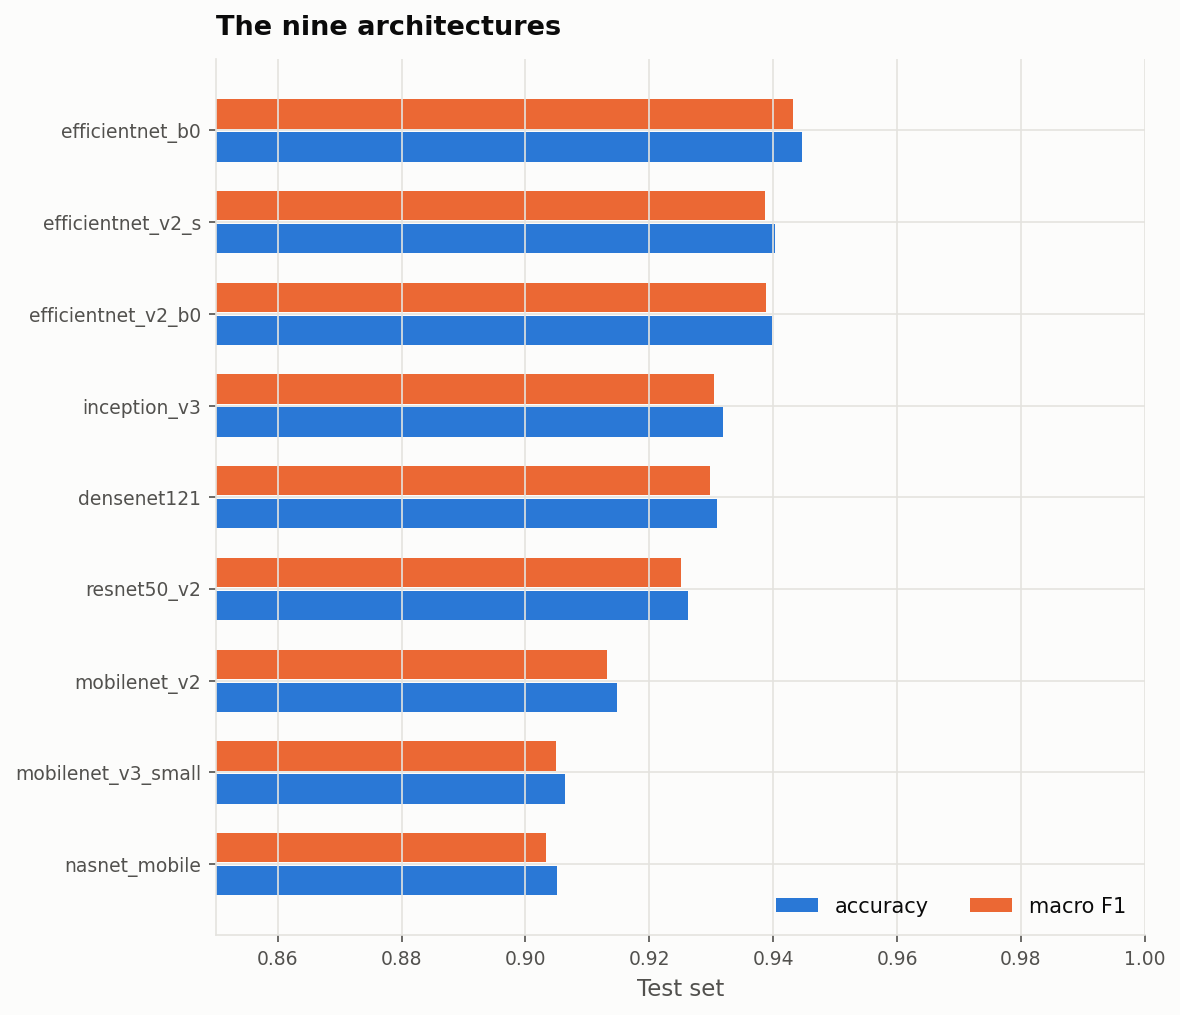

In [25]:
applyStyle()
import matplotlib.pyplot as plt

orden = comparacion.sort_values("validate_macro_f1")
y = range(len(orden))

fig, ax = plt.subplots(figsize=(8, 0.6 * len(orden) + 1.5))
ax.barh([i - 0.18 for i in y], orden["test_accuracy"], height=0.32, color=SERIE_1, label="accuracy")
ax.barh([i + 0.18 for i in y], orden["test_macro_f1"], height=0.32, color=SERIE_2, label="macro F1")
ax.set_yticks(list(y), orden["arquitectura"])
ax.set(xlim=(0.85, 1), xlabel="Test set", title="The nine architectures")
ax.legend(loc="lower right", ncol=2, frameon=False)
fig.tight_layout()
fig.savefig(FIGURAS / "accuracy_vs_macrof1.png", dpi=300, bbox_inches="tight")
plt.show()

## 3 · Calidad vs descarga

La latencia se reporta como referencia, pero se midió en CPU de escritorio: en
un navegador sobre WebGL/WASM y un teléfono de gama media es varias veces
mayor. La descarga, en cambio, es la misma en todas partes.

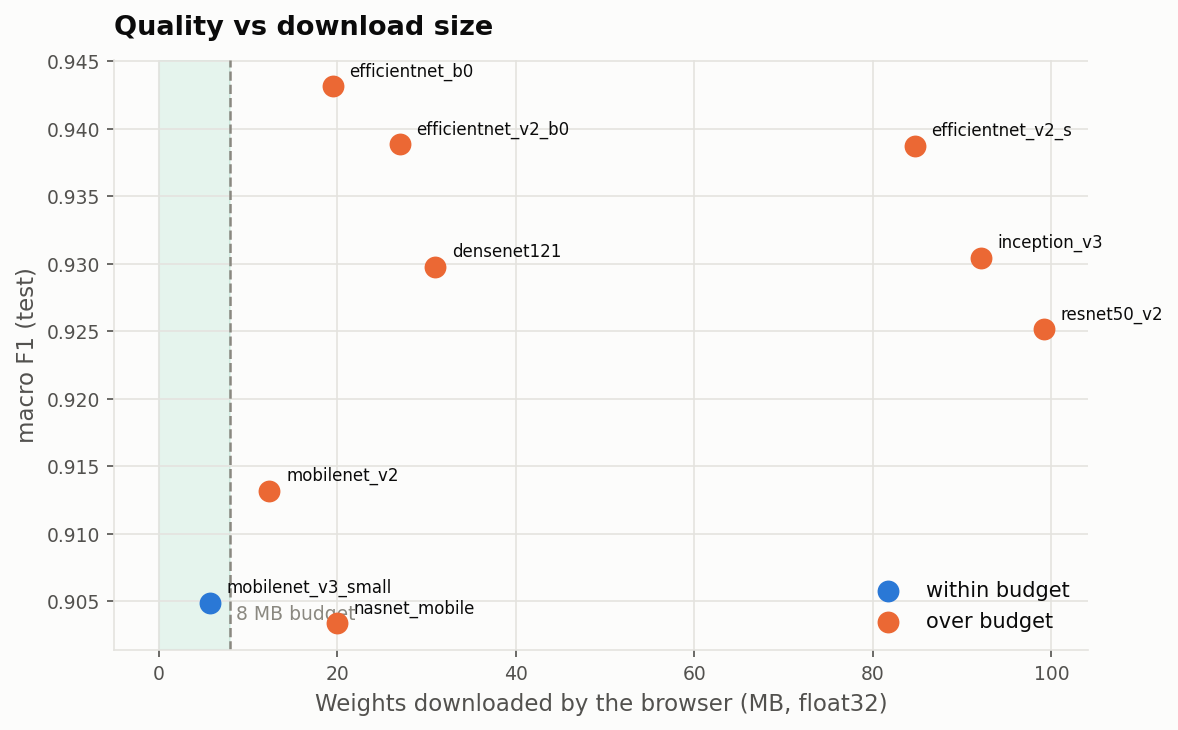

In [26]:
fig, ax = plt.subplots(figsize=(8, 5))
dentro = comparacion["pesos_MB"] <= PRESUPUESTO_MB

ax.axvspan(0, PRESUPUESTO_MB, color=SERIE_3, alpha=0.10)
ax.axvline(PRESUPUESTO_MB, color=INK_MUTED, linestyle="--", linewidth=1.2)
ax.text(PRESUPUESTO_MB, comparacion["test_macro_f1"].min(), f" {PRESUPUESTO_MB:.0f} MB budget",
        fontsize=9, va="bottom", color=INK_MUTED)
ax.scatter(comparacion.loc[dentro, "pesos_MB"], comparacion.loc[dentro, "test_macro_f1"],
           s=90, color=SERIE_1, label="within budget", zorder=3)
ax.scatter(comparacion.loc[~dentro, "pesos_MB"], comparacion.loc[~dentro, "test_macro_f1"],
           s=90, color=SERIE_2, label="over budget", zorder=3)
for _, f in comparacion.iterrows():
    ax.annotate(f["arquitectura"], (f["pesos_MB"], f["test_macro_f1"]),
                textcoords="offset points", xytext=(8, 5), fontsize=8)
ax.set(xlabel="Weights downloaded by the browser (MB, float32)", ylabel="macro F1 (test)",
       title="Quality vs download size")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIGURAS / "calidad_vs_descarga.png", dpi=300, bbox_inches="tight")
plt.show()

## 4 · Estudiante

El punto de partida de la destilación, y el mejor que cabe en el presupuesto entre las nueve arquitecturas.


In [27]:
candidatos = comparacion[comparacion["pesos_MB"] <= PRESUPUESTO_MB]
if candidatos.empty:
    raise ValueError(f"Ningún candidato cabe en {PRESUPUESTO_MB} MB")

estudiante = candidatos.iloc[0]
runEstudiante = runPorArquitectura[(estudiante["arquitectura"], estudiante["descongelado"])]

registro.writeJson(registro.OUTPUTS_DIR / "student.json", {
    "run_id": runEstudiante["run_id"],
    "architecture": estudiante["arquitectura"],
    "finetuning": float(estudiante["descongelado"]),
    "dataset": CORPUS,
    "test_accuracy": float(estudiante["test_accuracy"]),
    "test_macro_f1": float(estudiante["test_macro_f1"]),
    "validate_macro_f1": float(estudiante["validate_macro_f1"]),
    "top3_accuracy": float(estudiante["top3"]),
    "pesos_MB": float(estudiante["pesos_MB"]),
    "latencia_ms": float(estudiante["latencia_ms"]),
    "latencia_sd_ms": float(estudiante["latencia_sd_ms"]),
    "presupuesto_MB": PRESUPUESTO_MB,
})

print(f"Estudiante: {estudiante['arquitectura']} (descongelado {estudiante['descongelado']}) · "
      f"macro-F1 {estudiante['test_macro_f1']:.4f} · top-3 {estudiante['top3']:.4f} · "
      f"{estudiante['pesos_MB']:.1f} MB")

for _, f in comparacion[comparacion["pesos_MB"] > PRESUPUESTO_MB].iterrows():
    if f["validate_macro_f1"] > estudiante["validate_macro_f1"]:
        print(f"  queda fuera {f['arquitectura']}: {f['test_macro_f1'] - estudiante['test_macro_f1']:+.4f} "
              f"de macro-F1 en test y {f['top3'] - estudiante['top3']:+.4f} de top-3, "
              f"pero pesa {f['pesos_MB'] / estudiante['pesos_MB']:.1f}x más")

enInt8 = comparacion[comparacion["int8_MB"] <= PRESUPUESTO_MB]
mejorInt8 = enInt8.iloc[0]
print(f"\ncon el mismo presupuesto medido en int8 entrarían {len(enInt8)} de "
      f"{len(comparacion)} y ganaría {mejorInt8['arquitectura']} "
      f"({mejorInt8['test_macro_f1']:.4f} de macro-F1 en test, "
      f"{mejorInt8['int8_MB']:.1f} MB)")

Estudiante: mobilenet_v3_small (descongelado 0.3) · macro-F1 0.9049 · top-3 0.9626 · 5.7 MB
  queda fuera efficientnet_b0: +0.0383 de macro-F1 en test y +0.0158 de top-3, pero pesa 3.4x más
  queda fuera efficientnet_v2_s: +0.0339 de macro-F1 en test y +0.0136 de top-3, pero pesa 14.9x más
  queda fuera efficientnet_v2_b0: +0.0340 de macro-F1 en test y +0.0129 de top-3, pero pesa 4.7x más
  queda fuera inception_v3: +0.0256 de macro-F1 en test y +0.0127 de top-3, pero pesa 16.2x más
  queda fuera densenet121: +0.0249 de macro-F1 en test y +0.0087 de top-3, pero pesa 5.4x más
  queda fuera resnet50_v2: +0.0203 de macro-F1 en test y +0.0075 de top-3, pero pesa 17.4x más
  queda fuera mobilenet_v2: +0.0083 de macro-F1 en test y -0.0004 de top-3, pero pesa 2.2x más

con el mismo presupuesto medido en int8 entrarían 6 de 9 y ganaría efficientnet_b0 (0.9431 de macro-F1 en test, 4.9 MB)


## 5 · Docente

El techo del pool, y el punto de partida de la destilación. Si el mismo run
gana los dos roles no hay nada que destilar.

In [28]:
docente = comparacion.iloc[0]
runDocente = runPorArquitectura[(docente["arquitectura"], docente["descongelado"])]

registro.writeJson(registro.OUTPUTS_DIR / "teacher.json", {
    "run_id": runDocente["run_id"],
    "architecture": docente["arquitectura"],
    "dataset": CORPUS,
    "test_accuracy": float(docente["test_accuracy"]),
    "test_macro_f1": float(docente["test_macro_f1"]),
    "validate_macro_f1": float(docente["validate_macro_f1"]),
    "latencia_ms": float(docente["latencia_ms"]),
    "latencia_sd_ms": float(docente["latencia_sd_ms"]),
    "parametros_M": float(docente["parametros_M"]),
})

segundo = comparacion.iloc[1]
print(f"Docente: {docente['arquitectura']} · macro-F1 {docente['test_macro_f1']:.4f}")
print(f"Ventaja sobre el siguiente ({segundo['arquitectura']}): "
      f"{docente['test_macro_f1'] - segundo['test_macro_f1']:+.4f}")

brecha = docente["test_macro_f1"] - estudiante["test_macro_f1"]
if runDocente["run_id"] == runEstudiante["run_id"]:
    print("\nel mismo run gana ambos roles: destilar no aplica")
else:
    print(f"\nbrecha con el estudiante {estudiante['arquitectura']}: {brecha:+.4f}")

from scripts.kaggle import publicarArchivos
if Path("/kaggle").exists() and os.environ.get("GITHUB_TOKEN"):
    publicarArchivos(f"Select {estudiante['arquitectura']} as student and {docente['arquitectura']} as teacher",
                     "outputs/student.json", "outputs/teacher.json")

Docente: efficientnet_b0 · macro-F1 0.9431
Ventaja sobre el siguiente (efficientnet_v2_s): +0.0044

brecha con el estudiante mobilenet_v3_small: +0.0383


## 6 · ¿Cuáles de estas diferencias son reales?

In [29]:
verdad = registro.loadRunMetrics(comparacion.iloc[0]["run_id"])["splits"]["test"]["y_true"]

def predicciones(runId):
    prueba = registro.loadRunMetrics(runId)["splits"]["test"]
    assert prueba["y_true"] == verdad, f"{runId} no comparte el orden del test"
    return prueba["y_pred"]

lider = comparacion.iloc[0]
pares = [(f"{lider['arquitectura']} vs {f['arquitectura']}", lider["run_id"], f["run_id"])
         for _, f in comparacion.iloc[1:].iterrows()]
pares.append((f"docente vs estudiante ({docente['arquitectura']} vs {estudiante['arquitectura']})",
              docente["run_id"], estudiante["run_id"]))

filas = []
for etiqueta, a, b in pares:
    prueba = evalStats.mcnemar(verdad, predicciones(a), predicciones(b))
    filas.append({"comparacion": etiqueta, "solo_A": prueba["solo_a"],
                  "solo_B": prueba["solo_b"], "p": prueba["p"],
                  "veredicto": "indistinguibles" if prueba["p"] > 0.05 else "diferencia real"})

pareadas = pd.DataFrame(filas).drop_duplicates("comparacion").reset_index(drop=True)
empates = pareadas[(pareadas["p"] > 0.05) & (pareadas["comparacion"].str.startswith(lider["arquitectura"]))]
print(f"{lider['arquitectura']} no se distingue de {len(empates)} de los otros "
      f"{len(comparacion) - 1}: {', '.join(e.split(' vs ')[1] for _, e in empates['comparacion'].items()) or '—'}")
pareadas

efficientnet_b0 no se distingue de 2 de los otros 8: efficientnet_v2_s, efficientnet_v2_b0


,comparacion,solo_A,solo_B,p,veredicto
0,efficientnet_b0 vs efficientnet_v2_s,129,107,1.714995e-01,indistinguibles
1,efficientnet_b0 vs efficientnet_v2_b0,114,90,1.070988e-01,indistinguibles
2,efficientnet_b0 vs inception_v3,166,102,1.109977e-04,diferencia real
3,efficientnet_b0 vs densenet121,159,90,1.455122e-05,diferencia real
4,efficientnet_b0 vs resnet50_v2,183,90,1.895139e-08,diferencia real
5,efficientnet_b0 vs mobilenet_v2,227,76,1.268539e-18,diferencia real
6,efficientnet_b0 vs mobilenet_v3_small,266,73,6.419794e-27,diferencia real
7,efficientnet_b0 vs nasnet_mobile,273,73,2.653237e-28,diferencia real
8,docente vs estudiante (efficientnet_b0 vs mobi...,266,73,6.419794e-27,diferencia real


## Resumen

In [30]:
comparacion.drop(columns='run_id')

,arquitectura,descongelado,validate_macro_f1,test_macro_f1,f1_ic95,test_accuracy,acc_ic95,top3,parametros_M,pesos_MB,int8_MB,latencia_ms,latencia_sd_ms,minutos_entrenamiento
0,efficientnet_b0,0.3,0.942410,0.943134,"[0.9362, 0.9488]",0.944631,"[0.9380, 0.9506]",0.978446,4.89,19.5,4.9,192.2,6.2,193.6
1,efficientnet_v2_s,0.3,0.937357,0.938738,"[0.9314, 0.9445]",0.940281,"[0.9334, 0.9465]",0.976271,21.17,84.7,21.2,423.7,22.1,231.8
2,efficientnet_v2_b0,0.3,0.934114,0.938838,"[0.9316, 0.9446]",0.939885,"[0.9330, 0.9461]",0.975480,6.76,27.0,6.8,161.9,5.0,169.3
3,inception_v3,0.3,0.933359,0.930419,"[0.9228, 0.9365]",0.931975,"[0.9247, 0.9386]",0.975282,23.03,92.1,23.0,253.4,32.2,258.7
4,densenet121,0.3,0.928433,0.929776,"[0.9221, 0.9359]",0.930987,"[0.9237, 0.9377]",0.971327,7.74,31.0,7.7,325.8,62.4,328.4
5,resnet50_v2,0.3,0.925214,0.925146,"[0.9174, 0.9315]",0.926241,"[0.9187, 0.9331]",0.970140,24.79,99.2,24.8,239.0,24.7,272.5
6,mobilenet_v2,0.3,0.905801,0.913191,"[0.9046, 0.9201]",0.914772,"[0.9068, 0.9222]",0.962231,3.09,12.4,3.1,116.4,14.9,145.8
7,mobilenet_v3_small,0.3,0.903339,0.904865,"[0.8963, 0.9120]",0.906466,"[0.8981, 0.9142]",0.962626,1.42,5.7,1.4,67.7,3.9,80.8
8,nasnet_mobile,0.3,0.897855,0.903372,"[0.8946, 0.9104]",0.905082,"[0.8967, 0.9129]",0.964010,4.99,20.0,5.0,362.6,18.2,255.0
